In [106]:
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf 
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,precision_recall_curve

# **Project 2** : 
## Predict Subsciber Churn For a Surat DTH/ BroadBand Provider

In [58]:
# Loading The Dataset
df = pd.read_csv("surat_churn_data.csv")
df

,tenure_months,contract_type,monthly_bill,avg_data_usage_gb,complaint_count_6m,late_payment_count,competitor_offer_nearby,festival_discount_availed,customer_service_calls,locality,lucky_draw_entries,signup_weekday,churn
0,4.0,Prepaid,315.0,14.4,0,0,1,1,0,Katargam,3,3,0
1,4.3,Prepaid,731.0,26.8,0,1,1,0,4,City Light,4,6,0
2,21.4,Prepaid,546.0,23.1,0,1,1,0,0,Varachha,0,2,0
3,31.6,Prepaid,659.0,11.5,0,1,0,0,2,Katargam,5,3,0
4,22.6,Postpaid,692.0,16.3,1,0,0,0,2,City Light,2,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,51.9,Postpaid,554.0,7.4,0,0,0,0,0,Adajan,5,0,0
4996,8.0,Prepaid,363.0,15.3,0,2,0,0,1,Piplod,9,0,0
4997,38.9,Prepaid,150.0,2.1,0,1,0,0,0,City Light,3,3,0
4998,30.7,Prepaid,1119.0,25.4,0,0,1,0,1,Adajan,5,4,0


- From The Above Dataset We Can See That From The Given Columns We Have To Find Out And Create An Prediction System Which can Identify Whether An Customer Will Churn Or Not With The Help Of Given Columns.

### Q1 Explore the class balance and understand why plain accuracy is a misleading metric here.

In [59]:
# Now We Will Explore Class Imbalance And See Why More Accuracy Of Majority Class Is A Problem.
df["churn"].value_counts()

churn
0    4134
1     866
Name: count, dtype: int64

In [60]:
# Showing In Percentage
print(f"{df["churn"].value_counts(normalize=True) * 100}")

churn
0    82.68
1    17.32
Name: proportion, dtype: float64


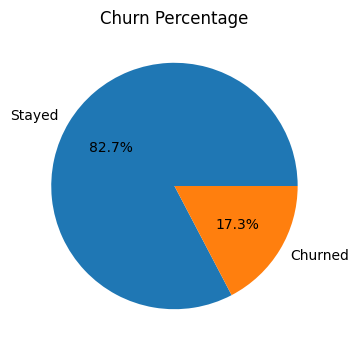

In [61]:
# Showing The Plot
plt.figure(figsize=(6,4))
df["churn"].value_counts().plot(kind="pie",autopct="%1.1f%%",labels=["Stayed", "Churned"])
plt.title("Churn Percentage")
plt.ylabel("")
plt.show()

- The churn dataset is imbalanced, with approximately 83% of subscribers belonging to the non-churn class and 17% belonging to the churn class. Because the majority class dominates the dataset, a model can achieve relatively high accuracy while performing poorly at identifying actual churners.

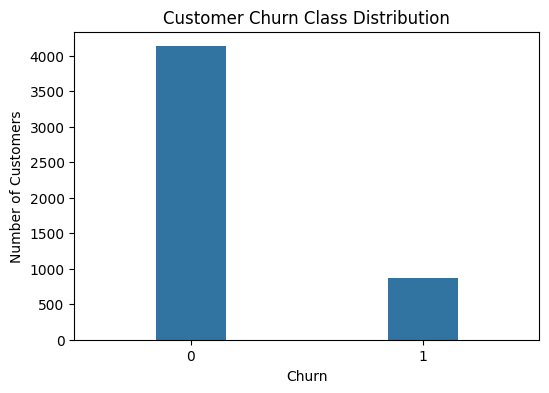

In [62]:
# Plotting The Class Imbalance
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="churn",width=0.3)
plt.title("Customer Churn Class Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

- Here 
- 0 : Stayed
- 1 : churned
- As We can See That Majority Of The Class Is 0 Which Means People Have stayed And Did Not Churned Which Will Tell The Model That most Of The People Never Goes And Every Time It Will Predict 0 Only Because It's Accuracy Has Become Biased.

### Q2 Preprocess: encode categoricals, scale numeric features, and use a stratified train/test split.

In [63]:
# Now We Will Encode Categorical Columns And Scale Numeric Features And Use An Stratified Train/Test Split

# Input And Target Variables
x = df.drop("churn",axis=1)
y = df["churn"]

# Stratified Train/Test Split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,stratify=y,random_state=42)

# Spliting The Dataset On Terms Of Category And Numeric
categorical_features = x.select_dtypes(include="object").columns.to_list()
numeric_features = x.select_dtypes(include="number").columns.to_list()

# Preprocessing Using ColumnTransformer
preprocessor = ColumnTransformer([
    ("num",StandardScaler(),numeric_features),
    ("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),categorical_features)
])

# Fitting Only On Training Data
x_train_preprocessed = preprocessor.fit_transform(x_train)

# Transforming On Testing Data
x_test_preprocessed = preprocessor.transform(x_test)

- Now We Have An Ready Input "X_train_preprocessed" To Be Feed Into An Tensorflow Neural Networks.

### Q3 Build a baseline neural network classifier trained on plain binary cross-entropy with no class balancing.

In [64]:
# Creating An Baseline Model Neural Network Classifier Which Will Train On Binary Cross Entropy With No Class Balancing
baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(x_train_preprocessed.shape[1],)),
    tf.keras.layers.Dense(128,activation="relu"),
    tf.keras.layers.Dense(64,activation="sigmoid"),
    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dense(1,activation="sigmoid")
])

# Compiling The Model
baseline_model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

# Training Or Fitting The Model
history_baseline = baseline_model.fit(
    x_train_preprocessed,
    y_train,
    validation_split = 0.3,
    epochs=20,
    batch_size=32,
    verbose=0
)

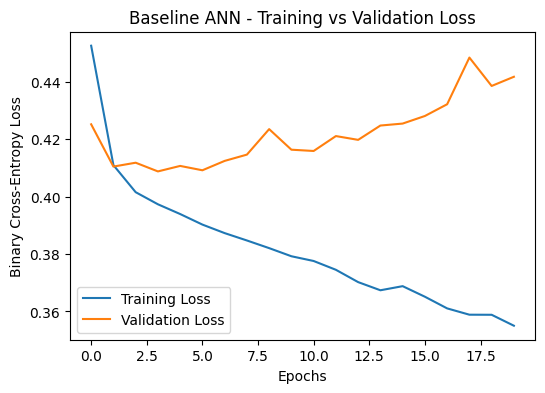

In [65]:
# Plotting Training Curve With Validation Curve
plt.figure(figsize=(6,4))
plt.plot(history_baseline.history["loss"],label="Training Loss")
plt.plot(history_baseline.history["val_loss"],label="Validation Loss")
plt.title("Baseline ANN - Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.show()

- From The Diagram We Can See That Training Curve Loss Is Slowly Decreasing Over Epochs But Validation Split Is Increasing Slightly Over Epochs Which Is Bed For The Model Because It Can Predict Incorrect Outputs.

### Q4 Report Accuracy, Precision, Recall, F1, and the confusion matrix for the baseline — specifically call out the recall on the churn (minority) class.

In [66]:
# Get Predictions To Evaluate The Baseline Model
y_prob_base = baseline_model.predict(x_test_preprocessed).ravel()             # It Gives Probabilities Between 0 And 1 

# So We Will Convert It Into Classes Using 0.5 as threshold
y_pred_base = (y_prob_base >= 0.5).astype(int)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [67]:
# Reporting The evaluation metrics
print("Accuracy :", round(accuracy_score(y_test, y_pred_base), 4))
print("Precision:", round(precision_score(y_test, y_pred_base), 4))
print("Recall   :", round(recall_score(y_test, y_pred_base), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_base), 4))
print("\nConfusion Matric :\n", confusion_matrix(y_test, y_pred_base))

Accuracy : 0.835
Precision: 0.58
Recall   : 0.1676
F1 Score : 0.2601

Confusion Matric :
 [[806  21]
 [144  29]]


- Now We Can See That In This Baseline Model Accuracy Is Good Because Model Predicted Right Which Was Right And It is 82 % Correct But Precision, Recall, F1-Score Are To Low, The Reason Would Be Class Imbalancing Because If Majority class Has More Values Or weightage it can Capture Or Diminish The Minority Class.

In [68]:
# Spcifically Calling Out The Minority Class Recall Score
print("Churn Recall:",round(recall_score(y_test, y_pred_base,pos_label=1), 4))

Churn Recall: 0.1676


- Now Here Pos_label Means recall_score For Minority class And You can See that it is very Low.
- It Means That The Model Detected Only 21 Percent Of The Customers Who Actually Churned.
- So even if The Accuracy Of The Model Is Good It Is Still Poor At Finding Churnes.

### Q5 Build an improved model using class weighting (or an alternative imbalance strategy of your choice) plus at least two of: Dropout, Batch Normalization, Early Stopping, L2 regularization.

In [69]:
# Building An Improved Model Using Class Imbalancing(SMOTE)

# Integrating SMOTE After Preprocessing done above
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train_preprocessed,y_train)

print("Before SMOTE:", np.bincount(y_train))
print("After SMOTE :", np.bincount(y_train_smote))

Before SMOTE: [3307  693]
After SMOTE : [3307 3307]


- Here SMOTE Creates Synthetic Examples Of Minority Class Which Are 1 And Increase Their Popularity Till it Is Same As Majority class
- And One Thing Is That We Have Used bincount Which Counts the Occurence Of Any number In Each Index Position.

In [78]:
# Creating The Improved Model
improved_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(x_train_smote.shape[1],)),
    tf.keras.layers.Dense(128,activation="relu",),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(64,activation="relu",),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(32,activation="relu",),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Compiling The Model
improved_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss="binary_crossentropy",metrics=["accuracy"])

In [79]:
# Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

# Fitting The Model
history_improved = improved_model.fit(
    x_train_smote,
    y_train_smote,
    validation_split=0.3,
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=0
)

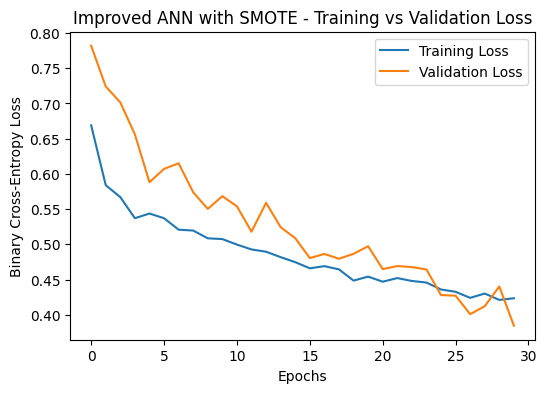

In [80]:
# Plotting Training Curve With Validation Curve
plt.figure(figsize=(6,4))
plt.plot(history_improved.history["loss"],label="Training Loss")
plt.plot(history_improved.history["val_loss"],label="Validation Loss")
plt.title("Improved ANN with SMOTE - Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.show()

- From The Diagram We Can See that Both Training Loss And Validation Loss Are Being Gradually Decreased With The Increasing epochs And The difference Between Them Is Also Minimal And Can Say That there are no signs Of Overfitting And Underfitting.

### Q6 Tune your decision threshold (do not just use 0.5) using the precision-recall curve, and justify the threshold you pick.

In [98]:
# Improved Model Evalaution
# Get Predictions To Evaluate The Improved Model
y_prob_imp = improved_model.predict(x_test_preprocessed).ravel()             # It Gives Probabilities Between 0 And 1 

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [99]:
# Finding The Best Thresholds Using Precision_recall_curve
precision, recall, thresholds = precision_recall_curve(y_test,y_prob_imp)

# Finding F1-Score Specifically As It Has Been Told In The Docx File
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-8)
)

# Taking The Index Position Of Every threshold And Showing the Best One
best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print("Best Threshold:", round(best_threshold, 4))
print("Best F1 Score:", round(best_f1, 4))

Best Threshold: 0.3308
Best F1 Score: 0.3654


- I selected this threshold because it achieved the highest F1 score, providing the best balance between precision and recall.
- It Provides A Good Balance Between Precision And recall For The Minority Churn Class.

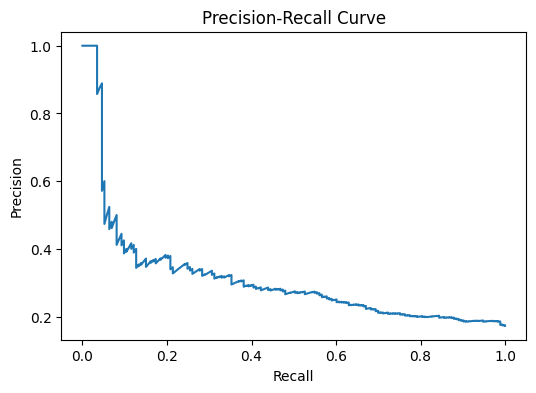

In [100]:
# Plotting Precision And Recall Curve
plt.figure(figsize=(6,4))
plt.plot(recall,precision,label="Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

- The Precision Recall Curve Indicates The Trade-Off Between Them, Identifying Actuall Churn Customers(recall) and avoiding Incorrect Churn Predictions(Precision) At Different Classification Thresholds.

In [101]:
# So We Will Convert It Into Classes Using Best threshold derived Above Using Precision_recall_curve
y_pred_imp = (y_prob_imp >= best_threshold).astype(int)

# Reporting The evaluation metrics
print("Accuracy :", round(accuracy_score(y_test, y_pred_imp), 4))
print("Precision:", round(precision_score(y_test, y_pred_imp), 4))
print("Recall   :", round(recall_score(y_test, y_pred_imp), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_imp), 4))
print("\nConfusion Matric :\n", confusion_matrix(y_test, y_pred_imp))

Accuracy : 0.67
Precision: 0.2738
Recall   : 0.5491
F1 Score : 0.3654

Confusion Matric :
 [[575 252]
 [ 78  95]]


- For Improved Model The Accuracy Of The Model Has Dropped But The Precision Recall And F1-Score Are Increased By A Little.
- But It Shows An Improvement Because Now The Model is All Over Good It Can Detect 40 To 55 Percent Of Customers Who Actually Churned.
- And For Confusion Matrix It is Also Improved An False Negative Are Decreased from The Baseline Model. 

### Q7 Report ROC-AUC and the full classification report for your final model.

In [105]:
# ROC-AUC using prediction probabilities
roc_auc = roc_auc_score(y_test, y_prob_imp)
print("ROC-AUC:", round(roc_auc, 4))

# Full Classification Report
print("\nClassification Report:")
print(classification_report(y_test,y_pred_imp))

ROC-AUC: 0.6453

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.70      0.78       827
           1       0.27      0.55      0.37       173

    accuracy                           0.67      1000
   macro avg       0.58      0.62      0.57      1000
weighted avg       0.78      0.67      0.71      1000



- The final model achieved a ROC-AUC From 60 to 70, indicating its ability to distinguish churn and non-churn customers. 
- The classification report shows the precision, recall, and F1-score for both classes, with particular attention to the minority churn class.

In [108]:
# Final Task Investigating The Irrelvant Columns
# Investigating If The Model Gives Any Importance To These Columns [lucky_draw_entries,signup_weekday]
result = permutation_importance(
    improved_model,
    x_test_preprocessed,
    y_test,
    scoring="r2",
    n_repeats=5,
    random_state=42
)

features = preprocessor.get_feature_names_out()

for feature, importance in zip(features, result.importances_mean):
    if "lucky_draw_entries" in feature or "signup_weekday" in feature:
        print(feature, ":", round(importance, 4))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
32/32 ━━━━━━━━━━━━━━━━━━━

- Permutation importance was used to check whether lucky_draw_entries and signup_weekday contribute to the model's predictions.
- Since these columns are intentionally irrelevant, their importance should ideally be close to zero.
- This indicates that the model is not relying significantly on these features for predicting churn.
- And From Conclusion we can see that these columns permutation scores are near to zero which means they have no relevance to the churn prediction.